# WGAN on GenHack 3 maize yields

This notebook trains a Wasserstein GAN with gradient penalty: the discriminator is replaced by a critic estimating the Wasserstein distance, which makes training more stable.

**Data:** Annual maize yields at 4 French weather stations (GenHack 3 challenge), keeping only years with normal weather. Years are independent, so the main goal is to reproduce the joint distribution of the 4 yields.

The architecture and hyperparameters below were found beforehand by optimisation (Metropolis-Hastings search, then Optuna). The last section shows how. Here we train the model with that configuration, compare generated and real data, and evaluate it.

Run this notebook from the repository root, with `data/data_genhack.csv` in place (the datasets are not distributed with the repository).

## Setup

In [1]:
import random

import numpy as np
import pandas as pd
import torch

from time_series_gan import WGAN
from time_series_gan.metrics import dWasserstein, dFrechet, ONND, score

# Fix random seeds so the outputs below can be reproduced
random.seed(0)
np.random.seed(0)
torch.manual_seed(0);

## Data

In [2]:
data = pd.read_csv("data/data_genhack.csv")
print(f"{data.shape[0]} rows, {data.shape[1]} column(s)")
data.head()

1000 rows, 4 column(s)


,YIELD1,YIELD2,YIELD3,YIELD4
0,10.39,5.54,5.77,6.61
1,8.49,4.39,8.65,6.86
2,6.12,4.07,6.34,6.04
3,10.60,4.77,3.93,6.08
4,8.60,4.40,5.58,3.51


## Optimised configuration

Found by `results_pkl/optimised_architectures.txt`. `layer_sizes` lists the size of each hidden layer; the last value is the output size.

In [3]:
params = {
    'lr_g': 0.0008328,
    'lr_c': 0.008314,
    'epochs': 140,
    'batch_size': 89,
    'latent_dim': 9,
    'n_critic': 1,
    'lambda_gp': 0.2247,
}

archi = {
    'generator': {'architecture': 'MLP', 'layer_sizes': [15, 4]},
    'critic': {'architecture': 'MLP', 'layer_sizes': [22, 64, 28, 1]},
}

## Training

`fit` returns the metrics chosen with `set_metrics`, as (train value, validation value). Lower is better.

In [4]:
model = WGAN()
model.set_data(data)
model.set_metrics({
    'dWasserstein': {'function': dWasserstein, 'metric_args': {}},
    'dFrechet': {'function': dFrechet, 'metric_args': {}},
    'ONND': {'function': ONND, 'metric_args': {}},
    'score': {'function': score, 'metric_args': {}},
})
results = model.fit(params=params, architectures=archi)
pd.DataFrame(results, index=['train', 'validation']).round(3)

fit took 38.365493 seconds


,dWasserstein,dFrechet,ONND,score
train,0.167,9.123,0.758,5.377
validation,0.260,6.154,1.147,6.646


## Generated vs real data

Years are independent here, so we compare the distribution of each station's yield:

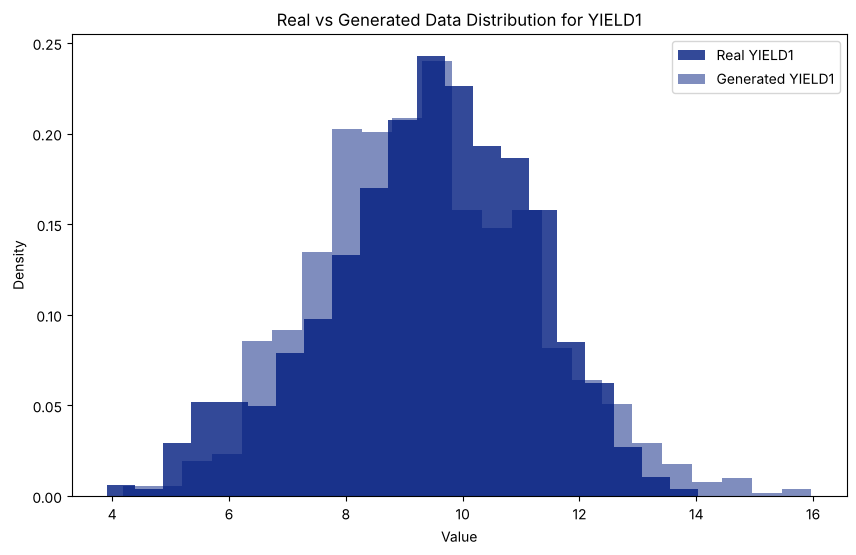

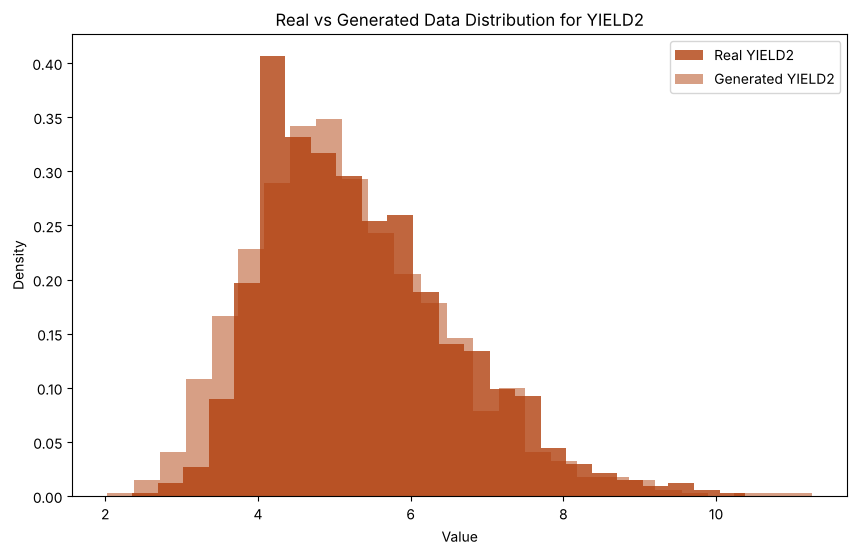

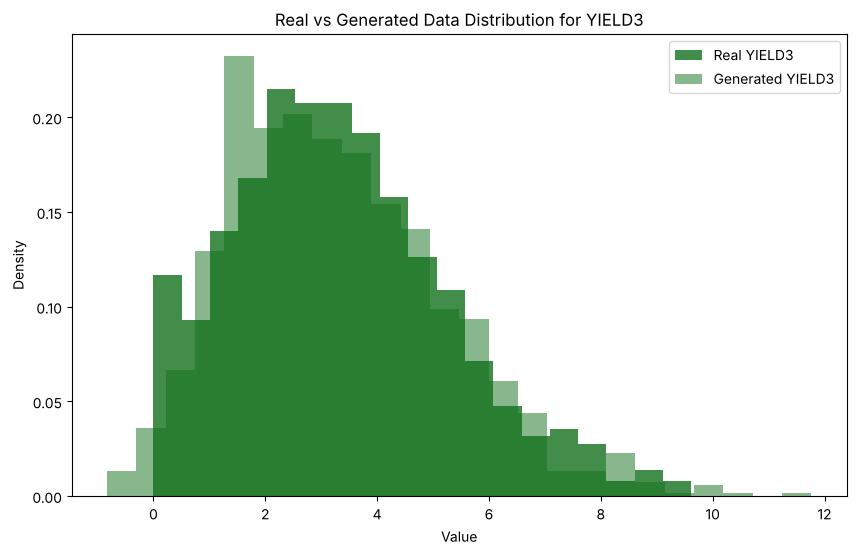

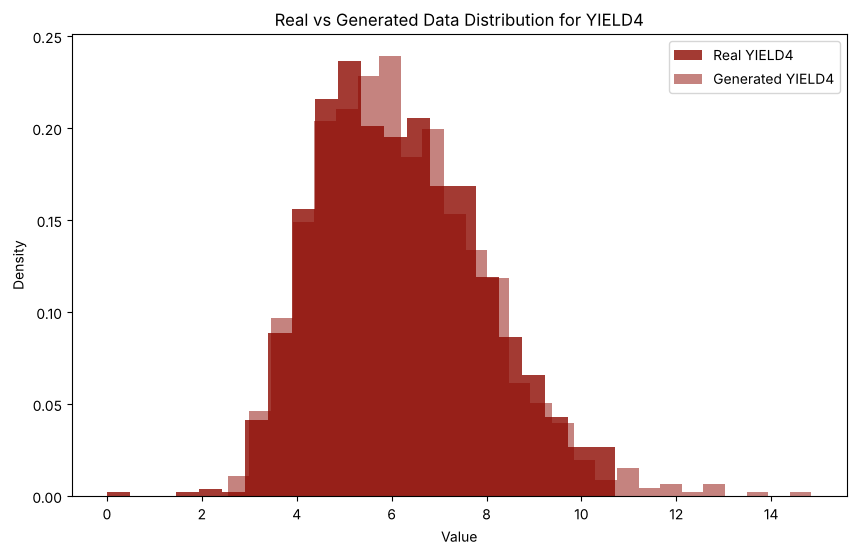

In [5]:
model.plot_histograms()

## Evaluation

Each metric is computed 20 times on the validation data, each time with newly generated samples, to get a mean and a standard deviation. Lower is better.

These values come from a single training run. GAN training varies a lot from one run to another, so they can differ from the results reported in the README, which come from the original runs.

In [6]:
n_runs = 20
metrics = {'Wasserstein': dWasserstein, 'Fréchet': dFrechet, 'ONND': ONND, 'Score': score}
values = {name: [model.compute_val_metric(f, {}) for _ in range(n_runs)] for name, f in metrics.items()}
pd.DataFrame({'mean': pd.DataFrame(values).mean(), 'std': pd.DataFrame(values).std()}).round(3)

,mean,std
Wasserstein,0.235,0.032
Fréchet,6.177,0.733
ONND,1.131,0.031
Score,6.494,0.703


## How the configuration was found

Not run here: these searches retrain the model hundreds of times and take hours. First, a Metropolis-Hastings search over architectures and hyperparameters (see `Optimisation_MH.py`):

```python
from Optimisation_MH import Metropolis_Hasting

archi = Metropolis_Hasting(0.1, data, WGAN, ite=1000, metrique=score, nom_de_la_métrique="score")
```

Then a Bayesian optimisation of the hyperparameters with Optuna:

```python
model = WGAN()
model.set_data(data)
model.fit_hyperparameters(
    {"lr_g": [5e-6, 5e-3], "lr_c": [5e-6, 5e-3], "epochs": [50, 150],
     "batch_size": [8, 100], "latent_dim": [1, 100], "n_critic": [1, 4], "lambda_gp": [0.01, 1]},
    n_trials=100,
)
print(model.parameters)
```